# **KẾT NỐI VÀ KIỂM TRA DỮ LIỆU**

In [80]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import time

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [81]:
OPCODE_PATH = Path(
    "/content/drive/MyDrive/IS6002/EXPERIMENT/implementation/data/raw/opcode_by_contract.csv"
)

df = pd.read_csv(OPCODE_PATH)

print("========== DATASET ==========")
print("Số hợp đồng:", len(df))
print("Số cột:", len(df.columns))

print("\nDanh sách cột đầu tiên:")
print(df.columns[:15].tolist())

print("\nPhân bố nhãn:")
print(df["label"].value_counts(dropna=False))

print("\nSố giá trị thiếu:")
print(df.isna().sum().sum())

print("\nSố contract_id trùng:")
print(df["contract_id"].duplicated().sum())

========== DATASET ==========
Số hợp đồng: 39905
Số cột: 258

Danh sách cột đầu tiên:
['contract_id', 'ADD', 'ADDMOD', 'ADDRESS', 'AND', 'BALANCE', 'BLOCKHASH', 'BYTE', 'CALL', 'CALLCODE', 'CALLDATACOPY', 'CALLDATALOAD', 'CALLDATASIZE', 'CALLER', 'CALLVALUE']

Phân bố nhãn:
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Số giá trị thiếu:
0

Số contract_id trùng:
0


# **EDA**

In [82]:
opcode_cols = [
    col for col in df.columns
    if col not in ["contract_id", "label"]
]

X_raw = df[opcode_cols].apply(pd.to_numeric, errors="coerce")

print("========== 1. TỔNG QUAN DATASET ==========")
print(f"Tổng số Smart Contract: {len(df):,}")
print(f"Số đặc trưng Opcode: {len(opcode_cols):,}")
print(f"Tổng số cột: {len(df.columns):,}")

print("\n========== 2. PHÂN BỐ NHÃN ==========")
print(df["label"].value_counts(dropna=False))

print("\nTỷ lệ (%):")
print(
    df["label"].value_counts(
        normalize=True, dropna=False
    ).mul(100).round(2)
)

print("\n========== 3. CHẤT LƯỢNG DỮ LIỆU ==========")
print("Contract ID trùng:", df["contract_id"].duplicated().sum())
print("Giá trị thiếu:", X_raw.isna().sum().sum())
print("Giá trị âm:", (X_raw < 0).sum().sum())
print("Đặc trưng toàn 0:", (X_raw.fillna(0).sum(axis=0) == 0).sum())
print(
    "Hợp đồng không có Opcode:",
    (X_raw.fillna(0).sum(axis=1) == 0).sum()
)

========== 1. TỔNG QUAN DATASET ==========
Tổng số Smart Contract: 39,905
Số đặc trưng Opcode: 256
Tổng số cột: 258

========== 2. PHÂN BỐ NHÃN ==========
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Tỷ lệ (%):
label
Vulnerable        70.29
Non-vulnerable    29.71
Name: proportion, dtype: float64

========== 3. CHẤT LƯỢNG DỮ LIỆU ==========
Contract ID trùng: 0
Giá trị thiếu: 0
Giá trị âm: 0
Đặc trưng toàn 0: 0
Hợp đồng không có Opcode: 0


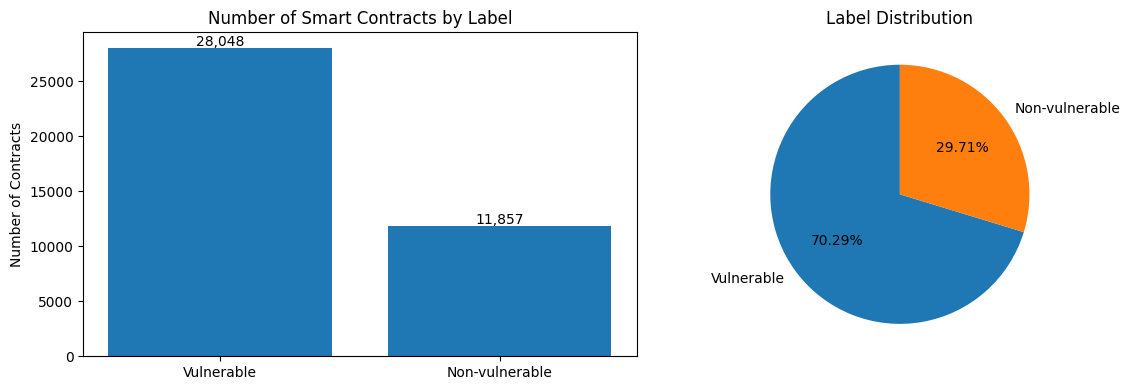

In [83]:
import matplotlib.pyplot as plt

label_counts = df["label"].value_counts()
label_percent = df["label"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(label_counts.index, label_counts.values)
axes[0].set_title("Number of Smart Contracts by Label")
axes[0].set_ylabel("Number of Contracts")

for i, value in enumerate(label_counts.values):
    axes[0].text(i, value + 200, f"{value:,}", ha="center")

axes[1].pie(
    label_counts.values,
    labels=label_counts.index,
    autopct="%1.2f%%",
    startangle=90
)
axes[1].set_title("Label Distribution")

plt.tight_layout()
plt.show()

========== THỐNG KÊ TỔNG OPCODE THEO NHÃN ==========
                count     mean  median      std  min     max
label                                                       
Non-vulnerable  11857  3902.46  3362.0  3029.55    6   31638
Vulnerable      28048  6995.52  4656.0  7681.78   21  148591


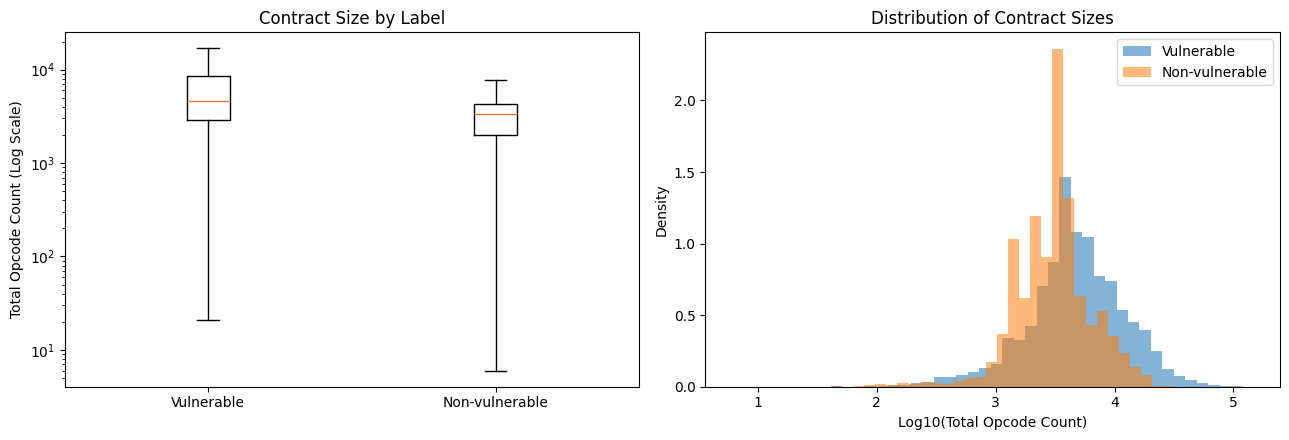

In [84]:
total_opcode = X_raw.sum(axis=1)

eda_size = pd.DataFrame({
    "label": df["label"],
    "total_opcode": total_opcode
})

print("========== THỐNG KÊ TỔNG OPCODE THEO NHÃN ==========")

stats = eda_size.groupby("label")["total_opcode"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(stats.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

groups = [
    eda_size.loc[
        eda_size["label"] == label, "total_opcode"
    ].values
    for label in ["Vulnerable", "Non-vulnerable"]
]

axes[0].boxplot(
    groups,
    tick_labels=["Vulnerable", "Non-vulnerable"],
    showfliers=False
)
axes[0].set_yscale("log")
axes[0].set_title("Contract Size by Label")
axes[0].set_ylabel("Total Opcode Count (Log Scale)")

for label in ["Vulnerable", "Non-vulnerable"]:
    values = eda_size.loc[
        eda_size["label"] == label, "total_opcode"
    ]
    axes[1].hist(
        np.log10(values),
        bins=40,
        alpha=0.55,
        density=True,
        label=label
    )

axes[1].set_title("Distribution of Contract Sizes")
axes[1].set_xlabel("Log10(Total Opcode Count)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

========== TỔNG QUAN OPCODE ==========
Số đặc trưng: 256
Opcode xuất hiện ở mọi hợp đồng: 2
Opcode xuất hiện trong dưới 1% hợp đồng: 134

========== TOP 15 OPCODE PHỔ BIẾN ==========
          total_count  contracts_present  presence_pct
PUSH1        33590182              39905        100.00
SWAP1        18459496              39900         99.99
POP          16981194              39895         99.97
DUP1         16827055              39904        100.00
PUSH2        13237636              39839         99.83
DUP2         13048360              39875         99.92
ADD          12347573              39818         99.78
JUMPDEST     10542382              39903         99.99
AND          10434935              39895         99.97
ISZERO        8470463              39901         99.99
MSTORE        8045067              39905        100.00
PUSH20        7986981              39793         99.72
SWAP2         7019444              39808         99.76
JUMPI         5924144              39902       

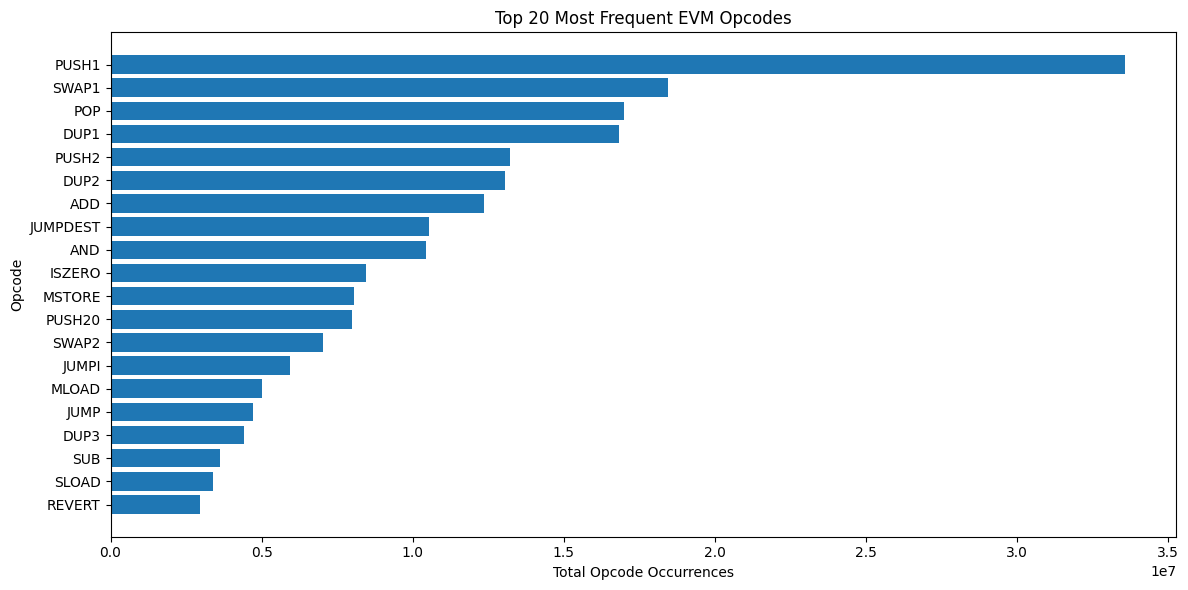

In [85]:
opcode_stats = pd.DataFrame({
    "total_count": X_raw.sum(axis=0),
    "contracts_present": (X_raw > 0).sum(axis=0),
    "mean": X_raw.mean(axis=0),
    "std": X_raw.std(axis=0)
})

opcode_stats["presence_pct"] = (
    opcode_stats["contracts_present"] / len(X_raw) * 100
)

opcode_stats = opcode_stats.sort_values(
    "total_count", ascending=False
)

print("========== TỔNG QUAN OPCODE ==========")
print("Số đặc trưng:", len(opcode_stats))
print("Opcode xuất hiện ở mọi hợp đồng:",
      (opcode_stats["presence_pct"] == 100).sum())
print("Opcode xuất hiện trong dưới 1% hợp đồng:",
      (opcode_stats["presence_pct"] < 1).sum())

print("\n========== TOP 15 OPCODE PHỔ BIẾN ==========")
print(
    opcode_stats[
        ["total_count", "contracts_present", "presence_pct"]
    ].head(15).round(2).to_string()
)

print("\n========== TOP 15 OPCODE ÍT PHỔ BIẾN ==========")
print(
    opcode_stats[
        ["total_count", "contracts_present", "presence_pct"]
    ].tail(15).round(2).to_string()
)

sparsity = (X_raw == 0).to_numpy().mean() * 100

print("\n========== SPARSITY ==========")
print(f"Tỷ lệ giá trị bằng 0: {sparsity:.2f}%")

top20 = opcode_stats.head(20)

plt.figure(figsize=(12, 6))
plt.barh(
    top20.index[::-1],
    top20["total_count"].values[::-1]
)

plt.title("Top 20 Most Frequent EVM Opcodes")
plt.xlabel("Total Opcode Occurrences")
plt.ylabel("Opcode")
plt.tight_layout()
plt.show()

# **DATA PREPROCESSING**

In [86]:
total_opcode = X_raw.sum(axis=1)

assert (total_opcode > 0).all(), (
    "Có hợp đồng có tổng Opcode bằng 0"
)

X_log = np.log1p(X_raw)

log_sums = X_log.sum(axis=1)

assert (log_sums > 0).all(), (
    "Có hợp đồng có tổng giá trị log bằng 0"
)

X_normalized = X_log.div(log_sums, axis=0)

row_sums = X_normalized.sum(axis=1)

assert np.allclose(row_sums, 1.0), (
    "Tổng tần suất chuẩn hóa không bằng 1"
)

assert np.isfinite(X_normalized.to_numpy()).all(), (
    "Dữ liệu chứa NaN hoặc Infinity"
)

assert list(X_normalized.columns) == opcode_cols, (
    "Thứ tự cột Opcode không được thay đổi"
)

print("========== LOG-NORMALIZED FREQUENCY ==========")

print("Kích thước dữ liệu:", X_normalized.shape)

print("\nGiá trị nhỏ nhất:")
print(X_normalized.min().min())

print("\nGiá trị lớn nhất:")
print(X_normalized.max().max())

print("\nTổng tần suất của 5 hợp đồng đầu:")
print(row_sums.head())

print("\nVí dụ 5 Opcode đầu của 3 hợp đồng:")
print(X_normalized.iloc[:3, :5].round(6))

========== LOG-NORMALIZED FREQUENCY ==========
Kích thước dữ liệu: (39905, 256)

Giá trị nhỏ nhất:
0.0

Giá trị lớn nhất:
0.2837910729958345

Tổng tần suất của 5 hợp đồng đầu:
0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64

Ví dụ 5 Opcode đầu của 3 hợp đồng:
        ADD  ADDMOD   ADDRESS       AND  BALANCE
0  0.031620     0.0  0.000000  0.028591      0.0
1  0.031296     0.0  0.000000  0.026967      0.0
2  0.026574     0.0  0.004957  0.025246      0.0


# **TRAINING**

In [87]:
from sklearn.model_selection import train_test_split

y = df["label"].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X_normalized,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("========== DATA SPLIT ==========")

for name, X, labels in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"\n{name}")
    print("Số hợp đồng:", f"{len(X):,}")
    print("Kích thước:", X.shape)
    print("Tỷ lệ nhãn (%):")
    print(
        labels.value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nChia dữ liệu thành công, không trùng hợp đồng giữa các tập.")

========== DATA SPLIT ==========

Train
Số hợp đồng: 27,933
Kích thước: (27933, 256)
Tỷ lệ nhãn (%):
label
Vulnerable        70.29
Non-vulnerable    29.71
Name: proportion, dtype: float64

Validation
Số hợp đồng: 5,986
Kích thước: (5986, 256)
Tỷ lệ nhãn (%):
label
Vulnerable        70.3
Non-vulnerable    29.7
Name: proportion, dtype: float64

Test
Số hợp đồng: 5,986
Kích thước: (5986, 256)
Tỷ lệ nhãn (%):
label
Vulnerable        70.28
Non-vulnerable    29.72
Name: proportion, dtype: float64

Chia dữ liệu thành công, không trùng hợp đồng giữa các tập.


========== ELBOW METHOD ==========
Thuật toán: MiniBatchKMeans
Số mẫu Train: 27933
Batch size: 256
Số seed mỗi k: 3
-----------------------------------------------------------------
k= 2 | Inertia mean=23.787047 | std=0.009828 | Epochs=20 | Steps=2182
k= 3 | Inertia mean=21.368616 | std=0.018843 | Epochs=20 | Steps=2182
k= 4 | Inertia mean=19.555416 | std=0.203971 | Epochs=20 | Steps=2182
k= 5 | Inertia mean=18.546198 | std=0.226578 | Epochs=20 | Steps=2182
k= 6 | Inertia mean=17.885086 | std=0.040620 | Epochs=20 | Steps=2182
k= 7 | Inertia mean=17.400667 | std=0.116680 | Epochs=20 | Steps=2182
k= 8 | Inertia mean=16.980457 | std=0.089475 | Epochs=20 | Steps=2182
k= 9 | Inertia mean=16.503882 | std=0.128477 | Epochs=20 | Steps=2182
k=10 | Inertia mean=16.260223 | std=0.047432 | Epochs=20 | Steps=2182

========== KẾT QUẢ ==========
 k  inertia_mean  inertia_std  improvement_pct
 2     23.787047     0.012037              NaN
 3     21.368616     0.023078        10.167009
 4     19.555416

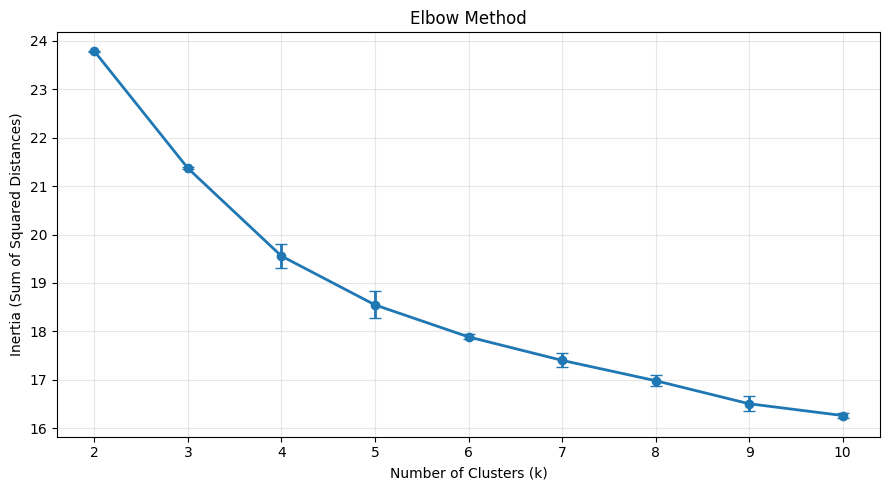

In [88]:
from sklearn.cluster import MiniBatchKMeans

K_VALUES = range(2, 11)

BATCH_SIZE = 256
RANDOM_STATE = 42

ELBOW_SEEDS = [42, 2024, 7]

results = []

X_train_np = X_train.to_numpy(dtype="float64")

print("========== ELBOW METHOD ==========")
print("Thuật toán: MiniBatchKMeans")
print("Số mẫu Train:", len(X_train_np))
print("Batch size:", BATCH_SIZE)
print("Số seed mỗi k:", len(ELBOW_SEEDS))
print("-" * 65)

for k in K_VALUES:

    for seed in ELBOW_SEEDS:

        model = MiniBatchKMeans(
        n_clusters=k,
        batch_size=BATCH_SIZE,
        init="k-means++",
        n_init=10,
        max_iter=20,
        tol=0.0,
        max_no_improvement=None,
        random_state=seed,
        compute_labels=True
        )

        model.fit(X_train_np)


        results.append({
            "k": k,
            "seed": seed,
            "inertia": model.inertia_,
            "epochs": model.n_iter_,
            "steps": model.n_steps_
        })

    k_inertia = [
        r["inertia"] for r in results if r["k"] == k
    ]

    print(
        f"k={k:2d} | "
        f"Inertia mean={np.mean(k_inertia):.6f} | "
        f"std={np.std(k_inertia):.6f} | "
        f"Epochs={model.n_iter_} | "
        f"Steps={model.n_steps_}",
        flush=True
    )

elbow_raw = pd.DataFrame(results)

elbow_df = (
    elbow_raw
    .groupby("k")
    .agg(
        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", "std")
    )
    .reset_index()
)

elbow_df["improvement_pct"] = (
    elbow_df["inertia_mean"].diff().abs()
    / elbow_df["inertia_mean"].shift(1) * 100
)

print("\n========== KẾT QUẢ ==========")
print(elbow_df.round(6).to_string(index=False))

assert (elbow_raw["epochs"] == 20).all(), (
    "Có mô hình dừng trước 20 epoch, inertia giữa các k không so sánh được"
)

print("\nTất cả mô hình đều chạy đủ 20 epoch.")

plt.figure(figsize=(9, 5))

plt.errorbar(
    elbow_df["k"],
    elbow_df["inertia_mean"],
    yerr=elbow_df["inertia_std"],
    marker="o",
    linewidth=2,
    capsize=4
)

plt.xticks(list(K_VALUES))
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Sum of Squared Distances)")
plt.title("Elbow Method")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [89]:
print("========== KHẢ NĂNG PHÂN BIỆT GIỮA CÁC k ==========")

separation = []

for i in range(1, len(elbow_df)):

    k_prev = int(elbow_df.loc[i - 1, "k"])
    k_curr = int(elbow_df.loc[i, "k"])

    gap = abs(
        elbow_df.loc[i, "inertia_mean"]
        - elbow_df.loc[i - 1, "inertia_mean"]
    )

    noise = 2 * max(
        elbow_df.loc[i - 1, "inertia_std"],
        elbow_df.loc[i, "inertia_std"]
    )

    separation.append({
        "pair": f"k={k_prev} -> k={k_curr}",
        "gap": gap,
        "noise_2std": noise,
        "improvement_pct": elbow_df.loc[i, "improvement_pct"],
        "distinguishable": gap > noise
    })

separation_df = pd.DataFrame(separation)

print(separation_df.round(6).to_string(index=False))

========== KHẢ NĂNG PHÂN BIỆT GIỮA CÁC k ==========
       pair      gap  noise_2std  improvement_pct  distinguishable
 k=2 -> k=3 2.418431    0.046156        10.167009             True
 k=3 -> k=4 1.813200    0.499626         8.485341             True
 k=4 -> k=5 1.009218    0.555000         5.160812             True
 k=5 -> k=6 0.661111    0.555000         3.564672             True
 k=6 -> k=7 0.484420    0.285808         2.708511             True
 k=7 -> k=8 0.420210    0.285808         2.414907             True
 k=8 -> k=9 0.476575    0.314703         2.806608             True
k=9 -> k=10 0.243659    0.314703         1.476373            False


In [90]:
K = 6
BATCH_SIZE = 256
RANDOM_STATE = 42

start = time.time()

kmeans_model = MiniBatchKMeans(
    n_clusters=K,
    init="k-means++",
    batch_size=BATCH_SIZE,
    n_init=10,
    max_iter=20,
    tol=0.0,
    max_no_improvement=None,
    random_state=RANDOM_STATE,
    compute_labels=True
)

kmeans_model.fit(X_train_np)

training_time = time.time() - start

train_clusters = kmeans_model.labels_ + 1
val_clusters = kmeans_model.predict(
    X_val.to_numpy(dtype="float64")
) + 1

print("========== TRAINING RESULT ==========")
print("Algorithm: MiniBatchKMeans")
print("Number of clusters:", K)
print("Batch size:", BATCH_SIZE)
print("Iterations:", kmeans_model.n_iter_)
print("Steps:", kmeans_model.n_steps_)
print("Training time:", f"{training_time:.2f} seconds")
print("Train inertia:", f"{kmeans_model.inertia_:.6f}")

assert kmeans_model.n_iter_ == 20, (
    "Mô hình dừng trước 20 epoch"
)

verify_model = MiniBatchKMeans(
    n_clusters=K,
    init="k-means++",
    batch_size=BATCH_SIZE,
    n_init=10,
    max_iter=40,
    tol=0.0,
    max_no_improvement=None,
    random_state=RANDOM_STATE,
    compute_labels=True
)

verify_model.fit(X_train_np)

gap_pct = (
    abs(verify_model.inertia_ - kmeans_model.inertia_)
    / kmeans_model.inertia_ * 100
)

print("\n========== CONVERGENCE CHECK ==========")
print("Inertia tại max_iter=20:", f"{kmeans_model.inertia_:.6f}")
print("Inertia tại max_iter=40:", f"{verify_model.inertia_:.6f}")
print("Mức cải thiện khi tăng gấp đôi số epoch:", f"{gap_pct:.4f}%")

print("\n========== TRAIN CLUSTER DISTRIBUTION ==========")

train_distribution = pd.Series(
    train_clusters,
    name="cluster"
).value_counts().sort_index()

print(train_distribution.to_string())

print("\n========== VALIDATION CLUSTER DISTRIBUTION ==========")

val_distribution = pd.Series(
    val_clusters,
    name="cluster"
).value_counts().sort_index()

print(val_distribution.to_string())

========== TRAINING RESULT ==========
Algorithm: MiniBatchKMeans
Number of clusters: 6
Batch size: 256
Iterations: 20
Steps: 2182
Training time: 1.23 seconds
Train inertia: 17.903880

========== CONVERGENCE CHECK ==========
Inertia tại max_iter=20: 17.903880
Inertia tại max_iter=40: 17.902052
Mức cải thiện khi tăng gấp đôi số epoch: 0.0102%

========== TRAIN CLUSTER DISTRIBUTION ==========
cluster
1    4594
2    2521
3    2834
4    7975
5    5151
6    4858

========== VALIDATION CLUSTER DISTRIBUTION ==========
cluster
1     937
2     558
3     648
4    1687
5    1084
6    1072


In [91]:
train_analysis = pd.DataFrame({
    "cluster": train_clusters,
    "label": y_train.to_numpy()
})

train_rate = pd.crosstab(
    train_analysis["cluster"],
    train_analysis["label"]
).reindex(
    index=range(1, K + 1),
    columns=["Vulnerable", "Non-vulnerable"],
    fill_value=0
)

train_rate.columns = ["n_vuln", "n_non_vuln"]

total_vuln = train_rate["n_vuln"].sum()
total_non_vuln = train_rate["n_non_vuln"].sum()

train_rate["vuln_pct"] = (
    train_rate["n_vuln"] / total_vuln * 100
)

train_rate["non_vuln_pct"] = (
    train_rate["n_non_vuln"] / total_non_vuln * 100
)

train_rate["assigned"] = np.where(
    train_rate["vuln_pct"] > train_rate["non_vuln_pct"],
    "Vulnerable",
    "Non-vulnerable"
)

VULNERABLE_CLUSTERS = set(
    train_rate.index[
        train_rate["assigned"] == "Vulnerable"
    ].tolist()
)

print("========== TRAIN CLUSTER LABEL MAPPING ==========")

print(train_rate.round(4).to_string())

print("\nVulnerable Clusters:", sorted(VULNERABLE_CLUSTERS))

print(
    "Non-vulnerable Clusters:",
    sorted(
        set(range(1, K + 1)) - VULNERABLE_CLUSTERS
    )
)

assert 0 < len(VULNERABLE_CLUSTERS) < K, (
    "Không phân biệt được hai nhóm cụm"
)

========== TRAIN CLUSTER LABEL MAPPING ==========
         n_vuln  n_non_vuln  vuln_pct  non_vuln_pct        assigned
cluster                                                            
1          4564          30   23.2466        0.3614      Vulnerable
2           713        1808    3.6316       21.7831  Non-vulnerable
3          2484         350   12.6522        4.2169      Vulnerable
4          7710         265   39.2706        3.1928      Vulnerable
5          1014        4137    5.1648       49.8434  Non-vulnerable
6          3148        1710   16.0342       20.6024  Non-vulnerable

Vulnerable Clusters: [1, 3, 4]
Non-vulnerable Clusters: [2, 5, 6]


========== VALIDATION EVALUATION ==========
Balanced Accuracy: 0.8248

========== CLASSIFICATION REPORT ==========
                precision    recall  f1-score   support

Non-vulnerable     0.5962    0.9100    0.7204      1778
    Vulnerable     0.9511    0.7395    0.8321      4208

      accuracy                         0.7902      5986
     macro avg     0.7736    0.8248    0.7762      5986
  weighted avg     0.8457    0.7902    0.7989      5986



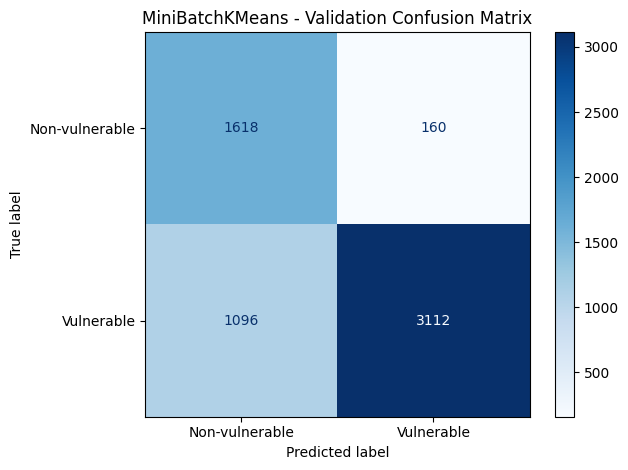

In [92]:
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_val_binary = (
    y_val.to_numpy() == "Vulnerable"
).astype(int)

y_val_pred = np.array([
    1 if cluster in VULNERABLE_CLUSTERS else 0
    for cluster in val_clusters
])

print("========== VALIDATION EVALUATION ==========")

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_val_binary, y_val_pred
        ), 4
    )
)

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_val_binary,
        y_val_pred,
        labels=[0, 1],
        target_names=[
            "Non-vulnerable",
            "Vulnerable"
        ],
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val_binary,
    y_val_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-vulnerable",
        "Vulnerable"
    ]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MiniBatchKMeans - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# **TESTING**

========== TEST EVALUATION ==========
Balanced Accuracy: 0.8346
Accuracy: 0.7992

========== CLASSIFICATION REPORT ==========
                precision    recall  f1-score   support

Non-vulnerable     0.6067    0.9219    0.7318      1779
    Vulnerable     0.9577    0.7473    0.8395      4207

      accuracy                         0.7992      5986
     macro avg     0.7822    0.8346    0.7857      5986
  weighted avg     0.8534    0.7992    0.8075      5986


========== TEST CLUSTER DISTRIBUTION ==========
cluster
1     977
2     550
3     664
4    1642
5    1091
6    1062
Name: count, dtype: int64

========== CONFUSION MATRIX (%) ==========

Non-vulnerable thực tế:
  dự đoán đúng Non-vulnerable: 92.19%
  dự đoán sai thành Vulnerable: 7.81%

Vulnerable thực tế:
  dự đoán sai thành Non-vulnerable: 25.27%
  dự đoán đúng Vulnerable: 74.73%


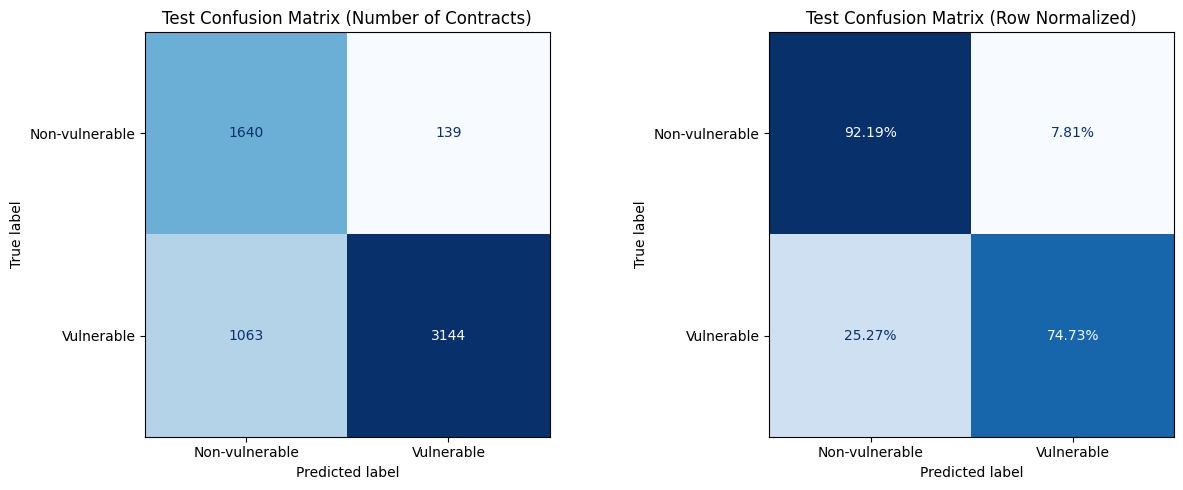

In [93]:
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

X_test_np = X_test.to_numpy(dtype="float64")

test_clusters = kmeans_model.predict(X_test_np) + 1

y_test_pred = np.array([
    1 if cluster in VULNERABLE_CLUSTERS else 0
    for cluster in test_clusters
])

y_test_binary = (
    y_test.to_numpy() == "Vulnerable"
).astype(int)

print("========== TEST EVALUATION ==========")

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test_binary, y_test_pred
        ), 4
    )
)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test_binary, y_test_pred
        ), 4
    )
)

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test_binary,
        y_test_pred,
        labels=[0, 1],
        target_names=[
            "Non-vulnerable",
            "Vulnerable"
        ],
        digits=4,
        zero_division=0
    )
)

print("\n========== TEST CLUSTER DISTRIBUTION ==========")

print(
    pd.Series(
        test_clusters,
        name="cluster"
    ).value_counts().sort_index()
)

cm = confusion_matrix(
    y_test_binary,
    y_test_pred,
    labels=[0, 1]
)

cm_percent = confusion_matrix(
    y_test_binary,
    y_test_pred,
    labels=[0, 1],
    normalize="true"
)

print("\n========== CONFUSION MATRIX (%) ==========")

print("\nNon-vulnerable thực tế:")
print("  dự đoán đúng Non-vulnerable:", f"{cm_percent[0, 0] * 100:.2f}%")
print("  dự đoán sai thành Vulnerable:", f"{cm_percent[0, 1] * 100:.2f}%")

print("\nVulnerable thực tế:")
print("  dự đoán sai thành Non-vulnerable:", f"{cm_percent[1, 0] * 100:.2f}%")
print("  dự đoán đúng Vulnerable:", f"{cm_percent[1, 1] * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

disp_count = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-vulnerable", "Vulnerable"]
)

disp_count.plot(
    cmap="Blues",
    values_format="d",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Test Confusion Matrix (Number of Contracts)")

disp_percent = ConfusionMatrixDisplay(
    confusion_matrix=cm_percent,
    display_labels=["Non-vulnerable", "Vulnerable"]
)

disp_percent.plot(
    cmap="Blues",
    values_format=".2%",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Test Confusion Matrix (Row Normalized)")

plt.tight_layout()
plt.show()

# **PCA**

========== PCA 2D ==========
Explained variance ratio: [0.3074 0.1404]
Tổng hai thành phần: 0.4477


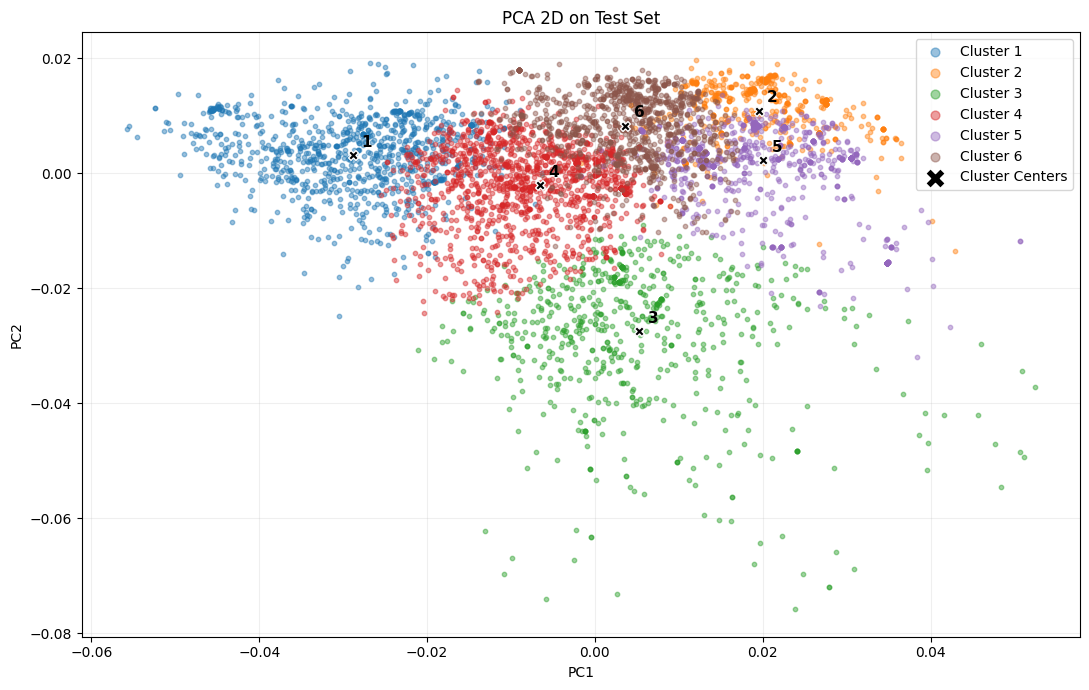

In [94]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(
    n_components=2,
    random_state=42
)

pca.fit(X_train_np)

X_test_pca = pca.transform(X_test_np)

centers_pca = pca.transform(
    kmeans_model.cluster_centers_
)

evr = pca.explained_variance_ratio_

print("========== PCA 2D ==========")
print("Explained variance ratio:", evr.round(4))
print("Tổng hai thành phần:", round(evr.sum(), 4))

plt.figure(figsize=(11, 7))

for cluster_id in range(1, K + 1):

    mask = test_clusters == cluster_id

    plt.scatter(
        X_test_pca[mask, 0],
        X_test_pca[mask, 1],
        s=10,
        alpha=0.45,
        label=f"Cluster {cluster_id}"
    )

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=50,
    c="black",
    edgecolors="white",
    linewidths=1,
    label="Cluster Centers",
    zorder=10
)

for i, center in enumerate(centers_pca):
    plt.annotate(
        str(i + 1),
        (center[0], center[1]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    f"PCA 2D on Test Set"
)

plt.legend(markerscale=2)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

========== PCA 3D ==========
Explained variance ratio: [0.3074 0.1404 0.0639]
Tổng ba thành phần: 0.5116


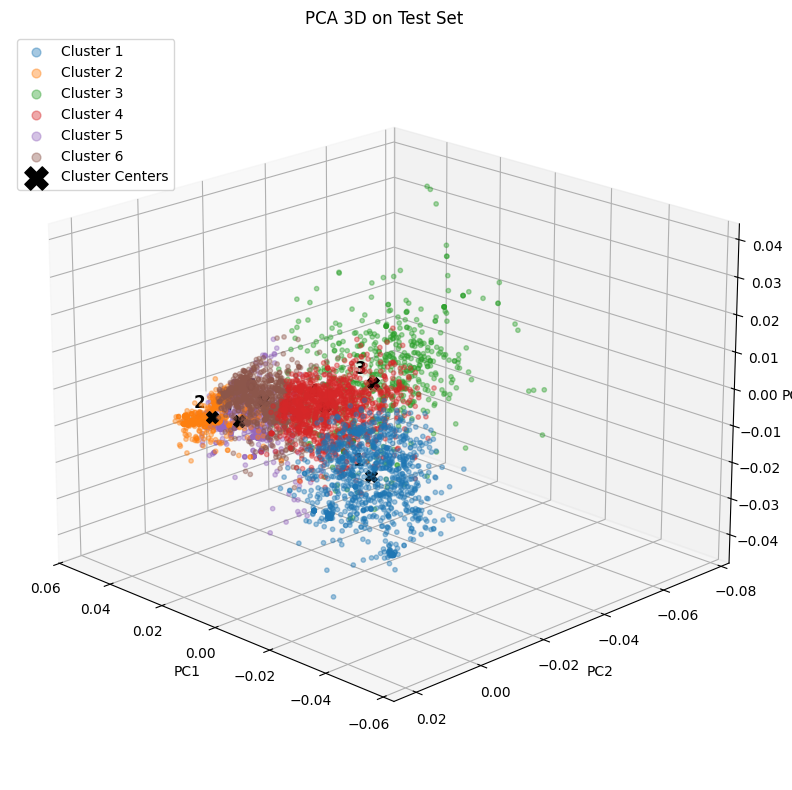

In [95]:
pca_3d = PCA(
    n_components=3,
    random_state=42
)

pca_3d.fit(X_train_np)

X_test_pca_3d = pca_3d.transform(X_test_np)

centers_pca_3d = pca_3d.transform(
    kmeans_model.cluster_centers_
)

evr_3d = pca_3d.explained_variance_ratio_

print("========== PCA 3D ==========")
print("Explained variance ratio:", evr_3d.round(4))
print("Tổng ba thành phần:", round(evr_3d.sum(), 4))

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

for cluster_id in range(1, K + 1):

    mask = test_clusters == cluster_id

    ax.scatter(
        X_test_pca_3d[mask, 0],
        X_test_pca_3d[mask, 1],
        X_test_pca_3d[mask, 2],
        s=10,
        alpha=0.4,
        label=f"Cluster {cluster_id}"
    )

ax.scatter(
    centers_pca_3d[:, 0],
    centers_pca_3d[:, 1],
    centers_pca_3d[:, 2],
    marker="X",
    s=70,
    c="black",
    depthshade=False,
    label="Cluster Centers"
)

label_offset = (
    X_test_pca_3d.max(axis=0) - X_test_pca_3d.min(axis=0)
) * 0.03

for i, center in enumerate(centers_pca_3d):
    ax.text(
        center[0] + label_offset[0],
        center[1] + label_offset[1],
        center[2] + label_offset[2],
        str(i + 1),
        fontsize=12,
        fontweight="bold",
        color="black",
        bbox=dict(
            boxstyle="round,pad=0.15",
            facecolor="white",
            alpha=0.75,
            edgecolor="none"
        )
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

ax.set_title("PCA 3D on Test Set")

ax.view_init(elev=20, azim=135)

ax.legend(loc="upper left", markerscale=2)

plt.tight_layout()
plt.show()